In [ ]:
# Load Data (Just like Section 1)

!pip install -q pyreadr
!git clone -q https://github.com/warint/tiger_woods.git

import pandas as pd
import pyreadr
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

df = pyreadr.read_r("tiger_woods/data/old/tiger_woods_sentiment.RDS")[None]

In [ ]:
# Same preprocessing as Part 1

df = df.sort_values(["Tournament_Year", "Tournament_Order", "Round_Number"])
df["next_score"] = df.groupby(["Tournament_Year", "Permanent_Tournament_Number"])["Round_Score"].shift(-1)
df["Interview_Text"] = df["Interview_Text"].fillna("").str.strip()
df = df[df["Interview_Text"] != ""]
df = df.dropna(subset=["next_score"])
df["label"] = (df["next_score"] <= 69).astype(int)
print("Rows:", len(df))

Rows: 380


In [ ]:
# Train/test split by time

# Train on earlier seasons, test on later seasons (no random shuffling,
# so the model is always predicting the "future").
train = df[df["Tournament_Year"] <= 2013]
test = df[df["Tournament_Year"] >= 2014]

X_train_text, y_train = train["Interview_Text"], train["label"]
X_test_text, y_test = test["Interview_Text"], test["label"]

print("Train:", len(train), "rows (1996-2013) | % label 1:", round(y_train.mean(), 2))
print("Test: ", len(test), "rows (2014-2020) | % label 1:", round(y_test.mean(), 2))

Train: 287 rows (1996-2013) | % label 1: 0.52
Test:  93 rows (2014-2020) | % label 1: 0.42


In [ ]:
# Turn text into numbers (TF-IDF)

# TF-IDF gives each word a weight: high if it appears often in this interview
# but rarely in others. Fit on TRAIN only so the test set stays unseen.
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                        min_df=3, max_features=5000)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("TF-IDF features:", X_train.shape[1])

TF-IDF features: 5000


In [ ]:
# Train the baseline models

models = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes (text)": MultinomialNB(),
    "Logistic Regression (text)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

# Non-text baseline: only Tiger's score in the round he just played.
# If the text models can't beat this, the words aren't adding anything.
score_model = LogisticRegression()
score_model.fit(train[["Round_Score"]], y_train)
pred = score_model.predict(test[["Round_Score"]])
prob = score_model.predict_proba(test[["Round_Score"]])[:, 1]
results.append({
    "Model": "Logistic Regression (round score only)",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1": f1_score(y_test, pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, prob),
})

results = pd.DataFrame(results).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority class,0.419,0.419,1.000,0.591,0.500
1,Naive Bayes (text),0.419,0.414,0.923,0.571,0.516
2,Logistic Regression (text),0.527,0.447,0.538,0.488,0.548
3,Logistic Regression (round score only),0.559,0.472,0.436,0.453,0.617


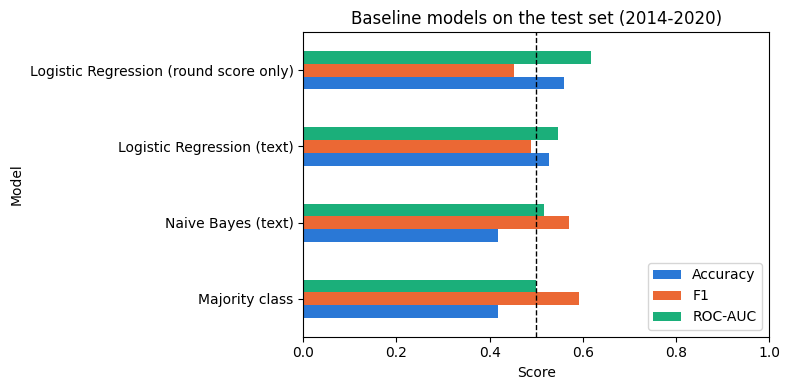

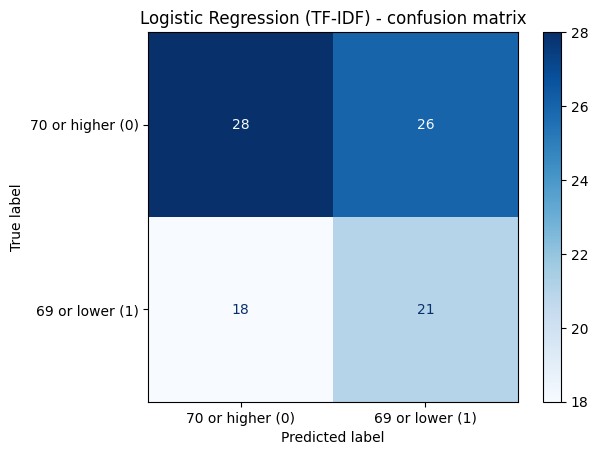

In [ ]:
# Compare models

results.set_index("Model")[["Accuracy", "F1", "ROC-AUC"]].plot(
    kind="barh", figsize=(8, 4), color=["#2a78d6", "#eb6834", "#1baf7a"])
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)   # coin-flip line
plt.title("Baseline models on the test set (2014-2020)")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Majority class always guesses the most common TRAIN label (1), which is the
# minority in the test set - so its F1 looks high but its accuracy is poor.

# Confusion matrix for the logistic regression text model
ConfusionMatrixDisplay.from_estimator(
    models["Logistic Regression (text)"], X_test, y_test,
    display_labels=["70 or higher (0)", "69 or lower (1)"], cmap="Blues")
plt.title("Logistic Regression (TF-IDF) - confusion matrix")
plt.show()

In [ ]:
# Words the logistic regression relies on

lr = models["Logistic Regression (text)"]
coefs = pd.Series(lr.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
print("Words pointing to 69 or lower (label 1):")
print(coefs.tail(10)[::-1].round(2))
print("\nWords pointing to 70 or higher (label 0):")
print(coefs.head(10).round(2))

Words pointing to 69 or lower (label 1):
hit           0.85
days          0.81
course        0.59
think         0.54
need          0.50
iron today    0.46
lot           0.44
read          0.41
people        0.41
sore          0.40
dtype: float64

Words pointing to 70 or higher (label 0):
grain   -0.49
tough   -0.44
hang    -0.43
mean    -0.40
wrong   -0.39
dad     -0.39
awful   -0.34
easy    -0.33
carry   -0.32
warm    -0.32
dtype: float64
